In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


In [2]:
# Helper functions
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

Board with 4 conflicts.


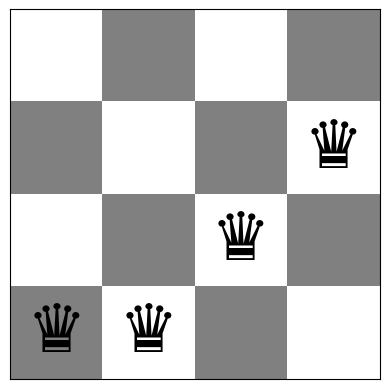

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
# Create a board
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

Board with 0 conflicts.


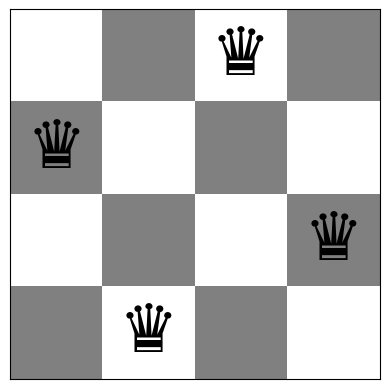

In [4]:
# A board 4 x 4 with no conflicts:
board = [1,3,0,2]
show_board(board)

In [5]:
# Task 1: Steepest-ascend Hill Climbing Search [20 Points]
# Code and description go here
def steepest_hc(start_board, max_steps=10000):
    board = np.array(start_board, dtype=int).copy()
    history = [conflicts(board)]

    for _ in range(max_steps):
        current = conflicts(board)
        best_value = current
        best_neighbors = []

        # Examine every possible one-queen move.
        for col in range(len(board)):
            for row in range(len(board)):
                if row == board[col]:
                    continue

                candidate = board.copy()
                candidate[col] = row
                value = conflicts(candidate)

                if value < best_value:
                    best_value = value
                    best_neighbors = [candidate]
                elif value == best_value and value < current:
                    best_neighbors.append(candidate)

        # No improving move: reached a local optimum.
        if not best_neighbors:
            break

        # Randomly break ties between equally good moves.
        board = best_neighbors[
            np.random.randint(len(best_neighbors))
        ]
        history.append(conflicts(board))

        if history[-1] == 0:
            break

    return board, history

In [6]:
# Task 2: Inefficient Stochastic Hill Climbing [10 Points]
# Code and description go here
def inefficient_stochastic_hc(start_board, max_steps=10000):
    board = np.array(start_board, dtype=int).copy()
    history = [conflicts(board)]

    for _ in range(max_steps):
        current = conflicts(board)
        improving_neighbors = []

        # Examine every possible one-queen move.
        for col in range(len(board)):
            for row in range(len(board)):
                if row == board[col]:
                    continue

                candidate = board.copy()
                candidate[col] = row

                if conflicts(candidate) < current:
                    improving_neighbors.append(candidate)

        # No improving move: reached a local optimum.
        if not improving_neighbors:
            break

        # Randomly choose among all improving neighbors.
        board = improving_neighbors[
            np.random.randint(len(improving_neighbors))
        ]
        history.append(conflicts(board))

        if history[-1] == 0:
            break

    return board, history

In [7]:
# Task 3: Efficient Stochastic Hill Climbing [20 Points]
def efficient_stochastic_hc(
    start_board, max_steps=100000, no_improve_limit=None
):
    board = np.array(start_board, dtype=int).copy()
    n = len(board)

    # Number of possible one-queen moves from a state.
    k = n * (n - 1)

    if no_improve_limit is None:
        no_improve_limit = max(
            1, math.ceil(k * math.log(max(k, 2) / 0.01))
        )

    current = conflicts(board)
    history = [current]
    failures = 0

    for _ in range(max_steps):
        candidate = random_neighbor(board)
        value = conflicts(candidate)

        if value < current:
            board = candidate
            current = value
            failures = 0
        else:
            failures += 1

        # Keep repeated values to show plateaus.
        history.append(current)

        if current == 0:
            break

        if failures >= no_improve_limit:
            break

    return board, history

In [11]:
def random_neighbor(board):
    """Tạo trạng thái lân cận bằng cách di chuyển một quân hậu."""

    candidate = np.array(board, dtype=int).copy()
    n = len(candidate)

    # Chọn ngẫu nhiên một cột.
    col = np.random.randint(n)

    # Chọn một hàng khác với hàng hiện tại.
    row = np.random.randint(n - 1)
    if row >= candidate[col]:
        row += 1

    candidate[col] = row
    return candidate

In [12]:
# Task 4: Hill Climbing Search with Random Restarts [10 Points]
# Code and description go here
import time
import math
import pandas as pd
from IPython.display import display

def random_restart(algorithm, n, max_restarts=100):
    start_time = time.perf_counter()

    best_board = None
    best_conflicts = float("inf")
    restarts_used = 0

    for restart in range(max_restarts):
        start_board = random_board(n)

        candidate, history = algorithm(start_board)
        score = conflicts(candidate)
        restarts_used += 1

        if score < best_conflicts:
            best_conflicts = score
            best_board = candidate.copy()

        # Stop early if an optimal solution is found.
        if best_conflicts == 0:
            break

    elapsed = time.perf_counter() - start_time

    return {
        "Board size": n,
        "Restarts used": restarts_used,
        "Best conflicts": best_conflicts,
        "Optimal": best_conflicts == 0,
        "Runtime (ms)": elapsed * 1000,
        "Best board": best_board.tolist()
    }


hc_algorithms = {
    "Steepest asc. HC": steepest_hc,
    "Ineff. Stochastic HC": inefficient_stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc
}

restart_results = []

# Use n=8 to examine the effect of local optima.
for name, algorithm in hc_algorithms.items():
    result = random_restart(algorithm, n=8, max_restarts=100)
    result["Algorithm"] = name
    restart_results.append(result)

display(pd.DataFrame(restart_results))

,Board size,Restarts used,Best conflicts,Optimal,Runtime (ms),Best board,Algorithm
0,8,5,0,True,36.258405,"[3, 5, 7, 2, 0, 6, 4, 1]",Steepest asc. HC
1,8,2,0,True,13.198312,"[4, 6, 1, 5, 2, 0, 7, 3]",Ineff. Stochastic HC
2,8,3,0,True,44.177378,"[6, 2, 0, 5, 7, 4, 1, 3]",Efficient Stochastic HC


In [19]:
# Task 4 — Thống kê số lần thành công của Random Restart
def summarize_random_restarts(
    name, algorithm, n=8, trials=100, max_restarts=100
):
    results = []

    # Repeat the complete random-restart experiment.
    for _ in range(trials):
        result = random_restart(
            algorithm,
            n=n,
            max_restarts=max_restarts
        )
        results.append(result)

    df = pd.DataFrame(results)

    success_count = int(df["Optimal"].sum())

    return {
        "Algorithm": name,
        "Board size": n,
        "Experiments": trials,
        "Successful experiments (h=0)": success_count,
        "Success rate (%)": success_count / trials * 100,
        "Average restarts": df["Restarts used"].mean(),
        "Average best h": df["Best conflicts"].mean(),
        "Best h observed": df["Best conflicts"].min(),
        "Average runtime (ms)": df["Runtime (ms)"].mean(),
        "Total runtime (s)": df["Runtime (ms)"].sum() / 1000
    }


restart_summary = []

for name, algorithm in hc_algorithms.items():
    summary = summarize_random_restarts(
        name,
        algorithm,
        n=8,
        trials=100,
        max_restarts=100
    )
    restart_summary.append(summary)

restart_table = pd.DataFrame(restart_summary)
display(restart_table.round(3))

,Algorithm,Board size,Experiments,Successful experiments (h=0),Success rate (%),Average restarts,Average best h,Best h observed,Average runtime (ms),Total runtime (s)
0,Steepest asc. HC,8,100,100,100.0,7.41,0.0,0,40.899,4.090
1,Ineff. Stochastic HC,8,100,100,100.0,7.49,0.0,0,33.113,3.311
2,Efficient Stochastic HC,8,100,100,100.0,6.35,0.0,0,63.823,6.382


In [13]:
# Task 5: Simulated Annealing [10 Points]
# Code and description go here
def temperature_at(
    iteration, T0, schedule, alpha, max_iter, Tmin=1e-3
):
    """Calculate the temperature at a given iteration."""

    if schedule == "geometric":
        return T0 * (alpha ** iteration)

    if schedule == "linear":
        return max(
            Tmin,
            T0 * (1 - iteration / max_iter)
        )

    if schedule == "logarithmic":
        return T0 / math.log(iteration + math.e)

    raise ValueError("Unknown annealing schedule")


def simulated_annealing(
    start_board,
    T0=2.0,
    alpha=0.995,
    max_iter=3000,
    schedule="geometric",
    Tmin=1e-3
):
    """Solve N-Queens using simulated annealing."""

    board = np.array(start_board, dtype=int).copy()
    current = conflicts(board)

    # Preserve the best solution found throughout the search.
    best_board = board.copy()
    best_value = current

    current_history = [current]
    best_history = [best_value]

    for iteration in range(max_iter):
        if best_value == 0:
            break

        temperature = temperature_at(
            iteration, T0, schedule, alpha, max_iter, Tmin
        )

        candidate = random_neighbor(board)
        candidate_value = conflicts(candidate)
        delta = candidate_value - current

        # Always accept improving or equal-quality moves.
        # Accept worse moves probabilistically.
        if (
            delta <= 0
            or (
                temperature > 0
                and np.random.random()
                < math.exp(-delta / temperature)
            )
        ):
            board = candidate
            current = candidate_value

        # Update the best solution found so far.
        if current < best_value:
            best_board = board.copy()
            best_value = current

        current_history.append(current)
        best_history.append(best_value)

    return best_board, current_history, best_history

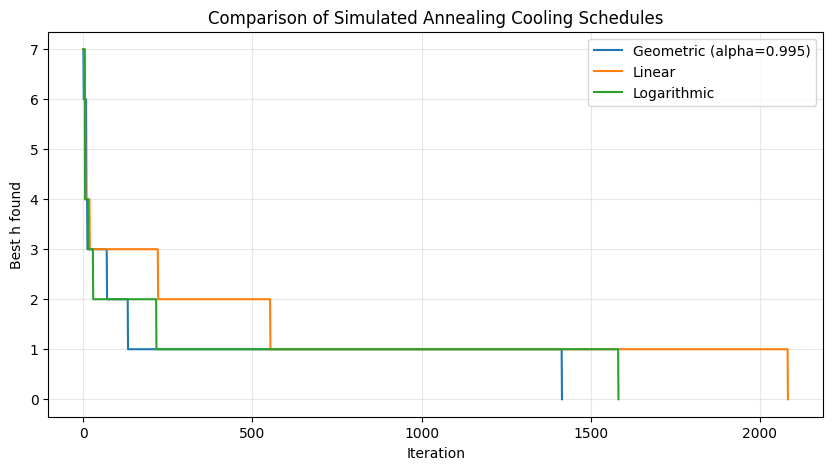

,Cooling schedule,Best h,Success (h=0),Iterations
0,Geometric (alpha=0.995),0,True,1415
1,Linear,0,True,2083
2,Logarithmic,0,True,1582


In [20]:
# Task 5 — Thử các lịch làm nguội khác nhau
# Geometric, Linear và Logarithmic.
np.random.seed(2026)

n = 8
start_board = random_board(n)

T0 = 2.0
max_iter = 3000

cooling_schedules = [
    ("Geometric (alpha=0.995)", "geometric", 0.995),
    ("Linear", "linear", 0.995),
    ("Logarithmic", "logarithmic", 0.995)
]

schedule_results = []

plt.figure(figsize=(10, 5))

for name, schedule, alpha in cooling_schedules:
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board.copy(),
            T0=T0,
            alpha=alpha,
            max_iter=max_iter,
            schedule=schedule
        )
    )

    best_h = conflicts(best_board)

    schedule_results.append({
        "Cooling schedule": name,
        "Best h": best_h,
        "Success (h=0)": best_h == 0,
        "Iterations": len(current_history) - 1
    })

    plt.plot(best_history, label=name)

plt.xlabel("Iteration")
plt.ylabel("Best h found")
plt.title("Comparison of Simulated Annealing Cooling Schedules")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

display(pd.DataFrame(schedule_results))

In [14]:
# Task 6
# Code
def sa_benchmark_runner(start_board):
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board,
            T0=2.0,
            alpha=0.995,
            max_iter=3000,
            schedule="geometric"
        )
    )

    # Evaluate the best solution found during the search.
    return best_board, best_history


comparison_algorithms = {
    "Steepest asc. HC": steepest_hc,
    "Ineff. Stochastic HC": inefficient_stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
    "Simulated Annealing": sa_benchmark_runner
}

comparison_rows = []

for n in [4, 8]:
    # Generate 100 different initial boards.
    initial_boards = [random_board(n) for _ in range(100)]

    for name, algorithm in comparison_algorithms.items():
        run_times = []
        final_conflict_counts = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            final_board, history = algorithm(
                initial_board.copy()
            )

            elapsed = time.perf_counter() - start_time

            run_times.append(elapsed)
            final_conflict_counts.append(
                conflicts(final_board)
            )

        run_times = np.array(run_times)
        final_conflict_counts = np.array(
            final_conflict_counts
        )

        comparison_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. Run time (ms)": (
                np.mean(run_times) * 1000
            ),
            "Avg. number of conflicts": np.mean(
                final_conflict_counts
            ),
            "% Optimal": (
                np.mean(final_conflict_counts == 0) * 100
            )
        })

comparison_table = pd.DataFrame(comparison_rows)

display(
    comparison_table.round(3)
)

,Algorithm,Board size,Avg. Run time (ms),Avg. number of conflicts,% Optimal
0,Steepest asc. HC,4,0.280,0.60,44.0
1,Ineff. Stochastic HC,4,0.338,0.77,35.0
2,Efficient Stochastic HC,4,1.053,0.81,33.0
3,Simulated Annealing,4,1.140,0.00,100.0
4,Steepest asc. HC,8,3.013,1.21,14.0
5,Ineff. Stochastic HC,8,4.409,1.27,12.0
6,Efficient Stochastic HC,8,10.005,1.30,12.0
7,Simulated Annealing,8,19.448,0.09,91.0


In [21]:
# Task 6 — Phân biệt thành công và nghiệm tốt nhất

In [22]:
def generate_unique_initial_boards(n, count=100):
    """Generate distinct board vectors for each experiment."""
    if count > n ** n:
        raise ValueError("Too many distinct initial boards requested.")

    boards = []
    seen = set()

    while len(boards) < count:
        board = np.random.randint(0, n, size=n)
        key = tuple(board.tolist())

        if key not in seen:
            seen.add(key)
            boards.append(board)

    return boards


def sa_benchmark_runner(start_board):
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board,
            T0=2.0,
            alpha=0.995,
            max_iter=3000,
            schedule="geometric"
        )
    )

    return best_board, best_history


comparison_algorithms = {
    "Steepest asc. HC": steepest_hc,
    "Ineff. Stochastic HC": inefficient_stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
    "Simulated Annealing": sa_benchmark_runner
}

np.random.seed(1234)

comparison_rows = []

for n in [4, 8]:
    # Use 100 distinct initial boards for each board size.
    initial_boards = generate_unique_initial_boards(n, 100)

    for name, algorithm in comparison_algorithms.items():
        run_times = []
        final_h_values = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            final_board, history = algorithm(
                initial_board.copy()
            )

            elapsed = time.perf_counter() - start_time

            run_times.append(elapsed)
            final_h_values.append(conflicts(final_board))

        final_h_values = np.array(final_h_values)

        success_count = int(np.sum(final_h_values == 0))

        comparison_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Runs": len(final_h_values),
            "Avg. runtime (ms)": np.mean(run_times) * 1000,
            "Avg. final h": np.mean(final_h_values),
            "Best h observed": np.min(final_h_values),
            "Successful runs (h=0)": success_count,
            "Success rate (%)": success_count / len(final_h_values) * 100
        })

comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(3))# Code
def sa_benchmark_runner(start_board):
    best_board, current_history, best_history = (
        simulated_annealing(
            start_board,
            T0=2.0,
            alpha=0.995,
            max_iter=3000,
            schedule="geometric"
        )
    )

    # Evaluate the best solution found during the search.
    return best_board, best_history


comparison_algorithms = {
    "Steepest asc. HC": steepest_hc,
    "Ineff. Stochastic HC": inefficient_stochastic_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc,
    "Simulated Annealing": sa_benchmark_runner
}

comparison_rows = []

for n in [4, 8]:
    # Generate 100 different initial boards.
    initial_boards = [random_board(n) for _ in range(100)]

    for name, algorithm in comparison_algorithms.items():
        run_times = []
        final_conflict_counts = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            final_board, history = algorithm(
                initial_board.copy()
            )

            elapsed = time.perf_counter() - start_time

            run_times.append(elapsed)
            final_conflict_counts.append(
                conflicts(final_board)
            )

        run_times = np.array(run_times)
        final_conflict_counts = np.array(
            final_conflict_counts
        )

        comparison_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. Run time (ms)": (
                np.mean(run_times) * 1000
            ),
            "Avg. number of conflicts": np.mean(
                final_conflict_counts
            ),
            "% Optimal": (
                np.mean(final_conflict_counts == 0) * 100
            )
        })

comparison_table = pd.DataFrame(comparison_rows)

display(
    comparison_table.round(3)
)

,Algorithm,Board size,Runs,Avg. runtime (ms),Avg. final h,Best h observed,Successful runs (h=0),Success rate (%)
0,Steepest asc. HC,4,100,0.421,0.60,0,45,45.0
1,Ineff. Stochastic HC,4,100,0.500,0.70,0,39,39.0
2,Efficient Stochastic HC,4,100,1.208,0.76,0,33,33.0
3,Simulated Annealing,4,100,1.186,0.00,0,100,100.0
4,Steepest asc. HC,8,100,2.915,1.27,0,21,21.0
5,Ineff. Stochastic HC,8,100,4.289,1.31,0,15,15.0
6,Efficient Stochastic HC,8,100,9.838,1.22,0,14,14.0
7,Simulated Annealing,8,100,18.791,0.03,0,97,97.0


,Algorithm,Board size,Avg. Run time (ms),Avg. number of conflicts,% Optimal
0,Steepest asc. HC,4,0.242,0.54,53.0
1,Ineff. Stochastic HC,4,0.317,0.71,44.0
2,Efficient Stochastic HC,4,0.978,0.76,39.0
3,Simulated Annealing,4,1.128,0.00,100.0
4,Steepest asc. HC,8,3.065,1.32,11.0
5,Ineff. Stochastic HC,8,4.534,1.16,12.0
6,Efficient Stochastic HC,8,9.705,1.27,15.0
7,Simulated Annealing,8,21.058,0.04,96.0


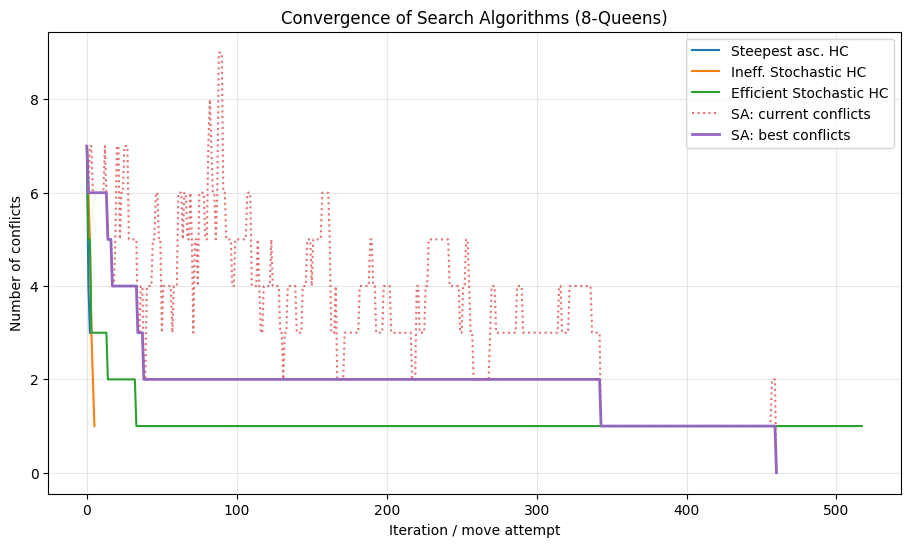

In [16]:
# Code and description go here
n = 8
start_board = random_board(n)

plt.figure(figsize=(11, 6))

# Plot the three Hill Climbing variants.
for name, algorithm in hc_algorithms.items():
    final_board, history = algorithm(start_board.copy())

    plt.plot(
        range(len(history)),
        history,
        label=name
    )

# Plot both current and best-so-far values for SA.
_, current_history, best_history = simulated_annealing(
    start_board.copy(),
    T0=2.0,
    alpha=0.995,
    max_iter=3000,
    schedule="geometric"
)

plt.plot(
    current_history,
    linestyle=":",
    alpha=0.65,
    label="SA: current conflicts"
)

plt.plot(
    best_history,
    linewidth=2,
    label="SA: best conflicts"
)

plt.xlabel("Iteration / move attempt")
plt.ylabel("Number of conflicts")
plt.title("Convergence of Search Algorithms (8-Queens)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
# Problem Size Scalability
# Code and description go here
scaling_algorithms = {
    "Steepest asc. HC": steepest_hc,
    "Efficient Stochastic HC": efficient_stochastic_hc
}

board_sizes = [4, 8, 12, 16, 20]
repeats = 30

scaling_rows = []

for n in board_sizes:
    # Use independent random starting boards.
    initial_boards = [
        random_board(n) for _ in range(repeats)
    ]

    for name, algorithm in scaling_algorithms.items():
        run_times = []

        for initial_board in initial_boards:
            start_time = time.perf_counter()

            final_board, history = algorithm(
                initial_board.copy()
            )

            elapsed = time.perf_counter() - start_time
            run_times.append(elapsed)

        scaling_rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. runtime (s)": np.mean(run_times)
        })

scaling_table = pd.DataFrame(scaling_rows)
display(scaling_table.round(6))

,Algorithm,Board size,Avg. runtime (s)
0,Steepest asc. HC,4,0.000330
1,Efficient Stochastic HC,4,0.001229
2,Steepest asc. HC,8,0.002995
3,Efficient Stochastic HC,8,0.009331
4,Steepest asc. HC,12,0.015183
5,Efficient Stochastic HC,12,0.034704
6,Steepest asc. HC,16,0.044998
7,Efficient Stochastic HC,16,0.084683
8,Steepest asc. HC,20,0.225287
9,Efficient Stochastic HC,20,0.159788


Steepest asc. HC: estimated exponent p = 3.91; empirical runtime approximately proportional to n^3.91 over the tested range.
Efficient Stochastic HC: estimated exponent p = 3.05; empirical runtime approximately proportional to n^3.05 over the tested range.


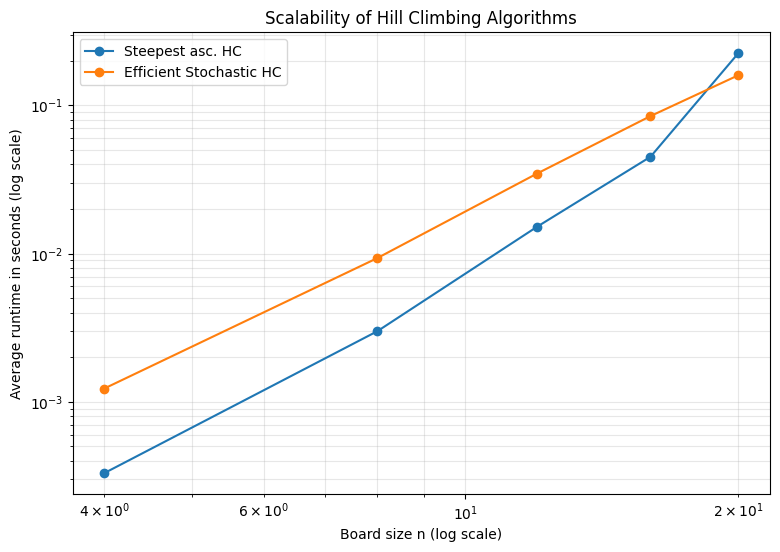

In [18]:
# Code and description go here
plt.figure(figsize=(9, 6))

for name in scaling_algorithms:
    subset = scaling_table[
        scaling_table["Algorithm"] == name
    ].sort_values("Board size")

    x = subset["Board size"].to_numpy(dtype=float)
    y = subset["Avg. runtime (s)"].to_numpy(dtype=float)

    plt.loglog(
        x, y,
        marker="o",
        label=name
    )

    # Fit log(time) = p * log(n) + intercept.
    p, intercept = np.polyfit(
        np.log(x), np.log(y), 1
    )

    print(
        f"{name}: estimated exponent p = {p:.2f}; "
        f"empirical runtime approximately proportional "
        f"to n^{p:.2f} over the tested range."
    )

plt.xlabel("Board size n (log scale)")
plt.ylabel("Average runtime in seconds (log scale)")
plt.title("Scalability of Hill Climbing Algorithms")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()